# Talento Tech 2026 — Clase 12
## Consolidación de Datos para Análisis

**Curso:** Data Analytics con Python

**Objetivo:** Aprender a preparar, limpiar, transformar y consolidar conjuntos de datos utilizando Pandas y NumPy, para facilitar su posterior análisis.

**Contenidos:**
1. Importación de bibliotecas.
2. Carga de conjuntos de datos.
3. Exploración inicial.
4. Limpieza de datos.
5. Transformación de datos.
6. Consolidación de datos.
7. Agrupación y agregación.

**Metodología:** Desarrollo progresivo de los ejemplos del PDF, aplicación práctica en Google Colab e interpretación de resultados.

### Paso 1 — Importación de bibliotecas

En este primer paso importamos las bibliotecas necesarias para trabajar con los datos.

- **Pandas (`pd`):** permite cargar, explorar, limpiar, transformar y combinar conjuntos de datos mediante DataFrames.
- **NumPy (`np`):** proporciona herramientas para realizar operaciones numéricas.

Las importaciones preparan el entorno de trabajo para ejecutar los procedimientos posteriores de la clase.

In [ ]:
import pandas as pd
import numpy as np

### Paso 2 — Carga de conjuntos de datos

**Objetivo:** conectar Google Drive y leer `ventas.csv` con Pandas. La conexión y búsqueda de la ruta son procedimientos auxiliares para localizar el archivo. El ejemplo del PDF utiliza `pd.read_csv()` para cargar un CSV en un DataFrame.

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


#### 2.1 — Localización del archivo

`os.walk()` recorre las carpetas de Mi unidad y muestra la ruta de `ventas.csv`. Esta búsqueda es un apoyo técnico, no una consigna del PDF.

In [ ]:

import os

for carpeta, subcarpetas, archivos in os.walk('/content/drive/MyDrive'):
    if 'ventas.csv' in archivos:
        print(os.path.join(carpeta, 'ventas.csv'))


/content/drive/MyDrive/2026 - Data Analytics con Python/ventas.csv
/content/drive/MyDrive/2026 - Data Analytics con Python/Data Sets Clase 12/ventas.csv


#### 2.2 — Lectura de `ventas.csv`

`pd.read_csv()` importa los registros al DataFrame `df`. El mensaje de confirmación indica que la lectura se completó; todavía no evalúa la calidad de los datos.

In [ ]:

df = pd.read_csv('/content/drive/MyDrive/2026 - Data Analytics con Python/ventas.csv')

print("Archivo ventas.csv cargado correctamente")


Archivo ventas.csv cargado correctamente


### Paso 3 — Exploración inicial de los datos

**Objetivo:** reconocer columnas, tipos, valores faltantes y estadísticas descriptivas antes de transformar los datos.

#### 3.1 — `head()`

Muestra las primeras cinco filas para observar la estructura y los formatos de `precio`, `cantidad` y `fecha_venta`.

In [ ]:

print(df.head())


   id_venta           producto   precio  cantidad fecha_venta  \
0       792  Cuadro decorativo   $69.94       5.0  02/01/2024   
1       811    Lámpara de mesa  $105.10       5.0  02/01/2024   
2      1156           Secadora   $97.96       3.0  02/01/2024   
3      1372           Heladera  $114.35       8.0  02/01/2024   
4      1546           Secadora  $106.21       4.0  02/01/2024   

           categoria  
0         Decoración  
1         Decoración  
2  Electrodomésticos  
3  Electrodomésticos  
4  Electrodomésticos  


#### 3.2 — `info()`

Informa la cantidad de registros, tipos de datos y valores no nulos. Se identificaron **3.035 registros**, seis columnas y dos valores faltantes en cada una de las columnas `precio` y `cantidad`. El `None` final aparece porque `info()` ya imprime el resumen y se lo llamó dentro de `print()`.

In [ ]:

print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3035 entries, 0 to 3034
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id_venta     3035 non-null   int64  
 1   producto     3035 non-null   object 
 2   precio       3033 non-null   object 
 3   cantidad     3033 non-null   float64
 4   fecha_venta  3035 non-null   object 
 5   categoria    3035 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 142.4+ KB
None


#### 3.3 — `describe()`

Resume las columnas numéricas. La cantidad media fue aproximadamente **6,50**, la mediana **7** y el rango observado **1 a 12** unidades. `id_venta` es un identificador: sus estadísticas no deben interpretarse como indicadores comerciales.

In [ ]:

print(df.describe())


          id_venta     cantidad
count  3035.000000  3033.000000
mean   1499.851400     6.496538
std     866.465379     3.457250
min       1.000000     1.000000
25%     748.500000     3.000000
50%    1502.000000     7.000000
75%    2249.500000     9.000000
max    3000.000000    12.000000


### Paso 4 — Limpieza de datos

**Objetivo:** detectar duplicados y datos faltantes antes de decidir cómo tratarlos. El PDF ejemplifica `drop_duplicates()` y el relleno hacia adelante (`ffill`); en este dataset no se aplicó `ffill`, porque copiar precios y cantidades de otra venta podría introducir errores.

#### 4.1 — Detección de filas duplicadas

`duplicated().sum()` identificó **35 filas completamente repetidas**.

In [ ]:

print(df.duplicated().sum())


35


#### 4.2 — Revisión de identificadores

Se encontraron **35 identificadores `id_venta` repetidos**. Al coincidir con los duplicados completos, no se detectaron repeticiones adicionales del identificador.

In [ ]:

print(df['id_venta'].duplicated().sum())


35


#### 4.3 — Eliminación de duplicados

`drop_duplicates(inplace=True)` elimina las filas completamente repetidas del DataFrame en memoria. Los registros pasan de **3.035 a 3.000**.

In [ ]:

df.drop_duplicates(inplace=True)

print("Registros después de eliminar duplicados:", len(df))


Registros después de eliminar duplicados: 3000


#### 4.4 — Conteo de valores faltantes

`isnull().sum()` muestra que siguen faltando dos precios y dos cantidades.

In [ ]:

print(df.isnull().sum())


id_venta       0
producto       0
precio         2
cantidad       2
fecha_venta    0
categoria      0
dtype: int64


#### 4.5 — Inspección de filas incompletas

Se identificaron dos ventas incompletas: **ID 627 (Elementos de cerámica)** e **ID 2171 (Parlantes Bluetooth)**. En ambas faltan precio y cantidad.

In [ ]:

print(df[df.isnull().any(axis=1)])


     id_venta               producto precio  cantidad fecha_venta    categoria
136       627  Elementos de cerámica    NaN       NaN  17/01/2024   Decoración
139      2171    Parlantes Bluetooth    NaN       NaN  17/01/2024  Electrónica


#### 4.6 — Tratamiento de registros incompletos

Como adaptación al dataset, `dropna(subset=[...])` excluye esas dos filas de los análisis que requieren ambos campos. Quedan **2.998 registros**, sin nulos en las columnas inspeccionadas. El CSV original de Drive no se sobrescribe.

In [ ]:

df.dropna(subset=['precio', 'cantidad'], inplace=True)

print("Registros después de la limpieza:", len(df))
print("Valores faltantes restantes:")
print(df.isnull().sum())


Registros después de la limpieza: 2998
Valores faltantes restantes:
id_venta       0
producto       0
precio         0
cantidad       0
fecha_venta    0
categoria      0
dtype: int64


### Paso 5 — Transformación de datos

**Objetivo:** convertir tipos de datos y crear variables útiles para el análisis.

#### 5.1 — Conversión de precios

Se elimina el símbolo `$` y `pd.to_numeric()` convierte `precio` de texto (`object`) a `float64`, apto para cálculos.

In [ ]:

df['precio'] = pd.to_numeric(
    df['precio'].str.replace('$', '', regex=False),
    errors='raise'
)

print(df['precio'].head())
print("Tipo de dato:", df['precio'].dtype)


0     69.94
1    105.10
2     97.96
3    114.35
4    106.21
Name: precio, dtype: float64
Tipo de dato: float64


#### 5.2 — Conversión de fechas

`pd.to_datetime(..., format="%d/%m/%Y")` interpreta las fechas como **día/mes/año** y las convierte a `datetime64[ns]`.

In [ ]:

df['fecha_venta'] = pd.to_datetime(
    df['fecha_venta'],
    format='%d/%m/%Y'
)

print(df['fecha_venta'].head())
print("Tipo de dato:", df['fecha_venta'].dtype)


0   2024-01-02
1   2024-01-02
2   2024-01-02
3   2024-01-02
4   2024-01-02
Name: fecha_venta, dtype: datetime64[ns]
Tipo de dato: datetime64[ns]


#### 5.3 — Creación de `total_venta`

Se calcula el importe por registro como **precio × cantidad**. Es una adaptación del ejemplo del PDF sobre creación de columnas.

In [ ]:

df['total_venta'] = df['precio'] * df['cantidad']

print(df[['producto', 'precio', 'cantidad', 'total_venta']].head())


            producto  precio  cantidad  total_venta
0  Cuadro decorativo   69.94       5.0       349.70
1    Lámpara de mesa  105.10       5.0       525.50
2           Secadora   97.96       3.0       293.88
3           Heladera  114.35       8.0       914.80
4           Secadora  106.21       4.0       424.84


### Paso 6 — Consolidación de datos

**Objetivo:** combinar información de distintos DataFrames cuando exista una relación válida. El PDF introduce `merge()`, `concat()` y `join()`; aquí se aplicó `merge()`.

#### 6.1 — Carga de clientes

Se lee `clientes.csv` para examinar sus campos antes de intentar relacionarlo con ventas.

In [ ]:

df_clientes = pd.read_csv(
    '/content/drive/MyDrive/2026 - Data Analytics con Python/clientes.csv'
)

print(df_clientes.head())


   id_cliente               nombre  edad         ciudad  ingresos
0           1      Aloysia Screase    44  Mar del Plata  42294.68
1           2  Kristina Scaplehorn    25        Posadas  24735.04
2           3       Filip Castagne    50    Resistencia  35744.85
3           4          Liuka Luard    39   Bahía Blanca  27647.96
4           5        Dore Cockshtt    28        Rosario  28245.65


#### 6.2 — Revisión de claves entre ventas y clientes

Ventas tiene `id_venta` y clientes tiene `id_cliente`, pero **no se encontró una clave de cliente en ventas**. No corresponde unir esos identificadores por su valor numérico.

In [ ]:

print("Columnas de ventas:")
print(df.columns.tolist())

print("\nColumnas de clientes:")
print(df_clientes.columns.tolist())


Columnas de ventas:
['id_venta', 'producto', 'precio', 'cantidad', 'fecha_venta', 'categoria', 'total_venta']

Columnas de clientes:
['id_cliente', 'nombre', 'edad', 'ciudad', 'ingresos']


#### 6.3 — Carga de marketing

`marketing.csv` incluye `producto`, una columna también presente en ventas. Se investiga si permite una consolidación descriptiva.

In [ ]:

df_marketing = pd.read_csv(
    '/content/drive/MyDrive/2026 - Data Analytics con Python/marketing.csv'
)

print(df_marketing.head())
print("\nColumnas:")
print(df_marketing.columns.tolist())


   id_campanha         producto  canal  costo fecha_inicio   fecha_fin
0           74  Adorno de pared     TV   4.81   20/03/2024  03/05/2024
1           12           Tablet   RRSS   3.40   26/03/2024  13/05/2024
2           32  Lámpara de mesa  Email   5.54   28/03/2024  20/04/2024
3           21       Smartphone   RRSS   6.37   29/03/2024  16/05/2024
4           58         Alfombra  Email   4.25   31/03/2024  05/05/2024

Columnas:
['id_campanha', 'producto', 'canal', 'costo', 'fecha_inicio', 'fecha_fin']


#### 6.4 — Revisión de productos repetidos

Se observaron **30 productos únicos** en cada archivo y **60 repeticiones del nombre de producto** en marketing. Una unión directa puede multiplicar filas de ventas.

In [ ]:

print("Productos únicos en ventas:", df['producto'].nunique())

print("Productos únicos en marketing:", df_marketing['producto'].nunique())

print("Productos repetidos en marketing:",
      df_marketing['producto'].duplicated().sum())


Productos únicos en ventas: 30
Productos únicos en marketing: 30
Productos repetidos en marketing: 60


#### 6.5 — Cantidad de campañas por producto

La agrupación confirma **tres campañas para cada uno de los 30 productos**. Este conteo se utiliza para preparar una unión controlada.

In [ ]:

print(
    df_marketing.groupby('producto').size()
)


producto
Adorno de pared           3
Alfombra                  3
Aspiradora                3
Auriculares               3
Batidora                  3
Cafetera                  3
Candelabro                3
Consola de videojuegos    3
Cortinas                  3
Cuadro decorativo         3
Cámara digital            3
Elementos de cerámica     3
Espejo decorativo         3
Freidora eléctrica        3
Heladera                  3
Horno eléctrico           3
Jarrón decorativo         3
Laptop                    3
Lavadora                  3
Lámpara de mesa           3
Microondas                3
Parlantes Bluetooth       3
Plancha de vapor          3
Proyector                 3
Rincón de plantas         3
Secadora                  3
SmartWatch                3
Smartphone                3
Tablet                    3
Televisor                 3
dtype: int64


#### 6.6 — Consolidación controlada con `merge()`

Primero se crea una tabla auxiliar con una fila por producto y su cantidad de campañas. Luego `merge(..., on="producto", how="inner", validate="many_to_one")` añade esa información a las ventas sin multiplicarlas: **2.998 registros**. Esta asociación no prueba que las campañas causaran las ventas.

In [ ]:

campanas_por_producto = (
    df_marketing.groupby('producto')
    .size()
    .reset_index(name='cantidad_campanas')
)

df_consolidado = pd.merge(
    df,
    campanas_por_producto,
    on='producto',
    how='inner',
    validate='many_to_one'
)

print(df_consolidado[
    ['producto', 'total_venta', 'cantidad_campanas']
].head())

print("Registros consolidados:", len(df_consolidado))


            producto  total_venta  cantidad_campanas
0  Cuadro decorativo       349.70                  3
1    Lámpara de mesa       525.50                  3
2           Secadora       293.88                  3
3           Heladera       914.80                  3
4           Secadora       424.84                  3
Registros consolidados: 2998


### Paso 7 — Agrupación y agregación de datos

**Objetivo:** resumir registros según una categoría mediante `groupby()` y funciones como `sum()`, `mean()` o `count()`.

#### 7.1 — Ventas totales por categoría

`groupby("categoria")["total_venta"].sum()` calcula el importe total por categoría. Resultados: **Electrodomésticos $505.299,63**, **Electrónica $482.577,80** y **Decoración $479.216,09**; total **$1.467.093,52**. Son importes de ventas, no cantidades de unidades.

In [ ]:

ventas_por_categoria = df_consolidado.groupby('categoria')['total_venta'].sum()

print(ventas_por_categoria)


categoria
Decoración           479216.09
Electrodomésticos    505299.63
Electrónica          482577.80
Name: total_venta, dtype: float64


---
## Actividad 1: Análisis de Ventas y Productos

### 1. Cargá los conjuntos de datos que contienen la información sobre las ventas, productos y clientes.

**Objetivo:** cargar los archivos `ventas.csv`, `productos.csv` y `clientes.csv` en DataFrames de Pandas mediante `pd.read_csv()`.

**Conexión a Google Drive**

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import pandas as pd

# Carpeta que contiene los datasets de la Clase 12
ruta = "/content/drive/MyDrive/2026 - Data Analytics con Python/Data Sets Clase 12/"

# Cargar los tres archivos CSV
ventas = pd.read_csv(ruta + "ventas.csv")
productos = pd.read_csv(ruta + "productos.csv")
clientes = pd.read_csv(ruta + "clientes.csv")

# Confirmar que se cargaron correctamente
print("Ventas:", ventas.shape)
print("Productos:", productos.shape)
print("Clientes:", clientes.shape)


Ventas: (919, 5)
Productos: (43, 5)
Clientes: (108, 5)


#### Resultados e interpretación

Se cargaron correctamente los tres conjuntos de datos utilizando `pd.read_csv()`:

- **Ventas:** 919 registros y 5 columnas.
- **Productos:** 43 registros y 5 columnas.
- **Clientes:** 108 registros y 5 columnas.

La propiedad `.shape` permitió verificar las dimensiones iniciales de cada DataFrame.

**Conclusión:** los tres datasets están disponibles para continuar con la exploración y el análisis. En esta etapa no se realizaron modificaciones sobre los datos originales.

### 2. Explorá cada DataFrame.

Se examinan las primeras filas, la estructura y las estadísticas descriptivas de ventas, productos y clientes.

**Exploración inicial del DataFrame de ventas**

**Objetivo:** conocer la estructura inicial del conjunto de datos de ventas.

Utilizamos el método `head()` de Pandas para visualizar las primeras cinco filas del DataFrame.

Esta exploración permite identificar los nombres de las columnas, observar ejemplos de sus valores y detectar posibles aspectos que debamos revisar posteriormente.

In [ ]:

# Visualizar las primeras cinco filas del dataset de ventas
ventas.head()


,ID_Venta,ID_Cliente,ID_Producto,Fecha,Cantidad
0,896,31,29,25/04/2025,5
1,358,97,11,21/07/2024,3
2,521,27,25,08/12/2024,10
3,384,6,5,28/10/2024,8
4,887,39,33,02/04/2025,1


**Examinar la estructura con info()**

In [ ]:

# Examinar la estructura y los tipos de datos
ventas.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 919 entries, 0 to 918
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ID_Venta     919 non-null    int64 
 1   ID_Cliente   919 non-null    int64 
 2   ID_Producto  919 non-null    int64 
 3   Fecha        919 non-null    object
 4   Cantidad     919 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 36.0+ KB


#### Interpretación de `ventas.info()`

El conjunto de datos contiene 919 registros y 5 columnas.

Las columnas `ID_Venta`, `ID_Cliente`, `ID_Producto` y `Cantidad` presentan el tipo de dato `int64`, mientras que `Fecha` aparece como `object`.

Todas las columnas tienen 919 valores no nulos, por lo que no se observan valores faltantes en esta revisión inicial.

**Estadísticas descriptivas con describe()**

In [ ]:

# Obtener estadísticas descriptivas del dataset de ventas
ventas.describe()


,ID_Venta,ID_Cliente,ID_Producto,Cantidad
count,919.000000,919.000000,919.000000,919.000000
mean,448.794342,52.286181,15.813928,5.420022
std,260.915357,29.224914,8.644339,2.821075
min,1.000000,1.000000,1.000000,1.000000
25%,220.500000,27.000000,8.000000,3.000000
50%,448.000000,53.000000,16.000000,5.000000
75%,674.500000,79.000000,23.000000,8.000000
max,900.000000,100.000000,35.000000,10.000000


#### Interpretación de `ventas.describe()`

El análisis estadístico se concentra en la variable `Cantidad`, ya que las demás columnas numéricas son identificadores.

Se analizaron 919 registros, con un promedio de 5,42 unidades por operación y una mediana de 5 unidades. La desviación estándar es de aproximadamente 2,82 unidades.

Las cantidades registradas varían entre 1 y 10 unidades. El primer cuartil es 3 y el tercer cuartil es 8, por lo que el 50 % central de las operaciones se encuentra entre esos valores.

**Exploración inicial del DataFrame de productos**

**Objetivo:** identificar las columnas y los valores del conjunto de datos de productos.

Utilizamos `productos.head()` para visualizar las primeras cinco filas y reconocer posibles claves de vinculación con el dataset de ventas, así como información sobre precios y categorías.

In [ ]:

# Visualizar las primeras cinco filas del dataset de productos
productos.head()


,ID_Producto,Nombre_Producto,Categoría,Precio_Unitario,Stock
0,29,Proyector,Multimedia,60.0,4
1,28,Altavoces portátiles,Audio y Sonido,7.0,55
2,14,Smartwatch / reloj inteligente,Wearables,50.0,35
3,21,Licuadora,Electrodomésticos,15.0,40
4,15,Calefón eléctrico,Electrodomésticos,95.0,10


#### Interpretación de `productos.head()`

El DataFrame de productos contiene las columnas `ID_Producto`, `Nombre_Producto`, `Categoría`, `Precio_Unitario` y `Stock`.

La columna `ID_Producto` constituye una posible clave de vinculación con el dataset de ventas.

Se identificaron variables que permiten conocer la denominación, clasificación, precio unitario y stock de los artículos.

**Estructura y tipos de datos de productos**

**Objetivo:** identificar los tipos de datos y la cantidad de valores no nulos de cada columna.

Utilizamos `productos.info()` para comprobar si los precios y el stock están almacenados como valores numéricos, si las categorías son variables de texto y si existen datos faltantes.

In [ ]:

# Examinar la estructura y los tipos de datos de productos
productos.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID_Producto      43 non-null     int64  
 1   Nombre_Producto  43 non-null     object 
 2   Categoría        43 non-null     object 
 3   Precio_Unitario  43 non-null     float64
 4   Stock            43 non-null     int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 1.8+ KB


#### Interpretación de `productos.info()`

El DataFrame de productos contiene 43 registros y 5 columnas.

Las variables `ID_Producto` y `Stock` presentan el tipo `int64`, mientras que `Precio_Unitario` es `float64`. Las columnas `Nombre_Producto` y `Categoría` están almacenadas como `object`.

Todas las columnas presentan 43 valores no nulos, por lo que no se identifican datos faltantes en esta exploración inicial.

**Estadísticas descriptivas de productos**

**Objetivo:** analizar la distribución de los precios unitarios y las cantidades disponibles en stock.

Utilizamos `productos.describe()` para obtener medidas como el promedio, la mediana, la desviación estándar, los cuartiles y los valores mínimos y máximos.

El análisis se concentrará en `Precio_Unitario` y `Stock`, ya que `ID_Producto` es un identificador y sus estadísticas no tienen una interpretación comercial relevante.

In [ ]:

# Obtener estadísticas descriptivas del dataset de productos
productos.describe()


,ID_Producto,Precio_Unitario,Stock
count,43.000000,43.000000,43.000000
mean,16.790698,73.569767,29.883721
std,10.418752,71.519776,30.467945
min,1.000000,2.000000,4.000000
25%,8.000000,14.000000,10.000000
50%,15.000000,45.000000,20.000000
75%,25.500000,120.000000,40.000000
max,36.000000,250.000000,150.000000


**Exploración inicial del DataFrame de clientes**

**Objetivo:** conocer las columnas y los valores del conjunto de datos de clientes.

Utilizamos `clientes.head()` para visualizar las primeras cinco filas, identificar la información disponible y verificar si existe una clave de vinculación con las ventas.

In [ ]:

# Visualizar las primeras cinco filas del dataset de clientes
clientes.head()


,ID_Cliente,Nombre,Edad,Ciudad,Ingresos
0,10,Yolanda Wren,28,Vicente López,$899700.72
1,91,Winona Jamme,35,Adrogué,$669747.95
2,34,Elora Howford,29,Tres de Febrero,$710610.80
3,29,Ennis Dilley,33,Morovín,$2015751.52
4,30,Baily Habercham,32,Esteban Echeverría,$1885401.91


#### Interpretación de `clientes.head()`

El DataFrame de clientes contiene las columnas `ID_Cliente`, `Nombre`, `Edad`, `Ciudad` e `Ingresos`.

Se identificó la columna `ID_Cliente` como posible clave de vinculación con el dataset de ventas.

La variable `Ingresos` presenta valores acompañados del símbolo `$`, por lo que será necesario verificar su tipo de dato y evaluar una transformación a formato numérico.

In [ ]:
clientes.info()
clientes.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   ID_Cliente  108 non-null    int64 
 1   Nombre      108 non-null    object
 2   Edad        108 non-null    int64 
 3   Ciudad      108 non-null    object
 4   Ingresos    108 non-null    object
dtypes: int64(2), object(3)
memory usage: 4.3+ KB


,ID_Cliente,Edad
count,108.000000,108.00000
mean,47.537037,33.12037
std,29.831122,4.42110
min,1.000000,21.00000
25%,19.750000,30.00000
50%,46.500000,33.00000
75%,73.250000,36.00000
max,100.000000,45.00000


#### Conclusión de la consigna 2

Se exploraron los tres conjuntos de datos mediante `head()`, `info()` y `describe()`.

- **Ventas:** 919 registros y 5 columnas. La columna `Fecha` requiere conversión a `datetime`.
- **Productos:** 43 registros y 5 columnas. `Precio_Unitario` es numérico.
- **Clientes:** 108 registros y 5 columnas. La edad promedio es de 33,12 años y `Ingresos` está almacenada como texto.

No se detectaron valores nulos mediante `info()`. Queda pendiente comprobar duplicados, integridad de identificadores y formatos durante la limpieza.

### 3. Limpiá los datos, eliminando duplicados y manejando valores nulos. Asegurate de que las columnas de fecha estén en el formato adecuado.

Se diagnostican duplicados y valores faltantes, se eliminan filas repetidas y se ajustan los tipos de datos.

In [ ]:

# Consigna 3 — Diagnóstico inicial de calidad de datos

for nombre, df in {
    "Ventas": ventas,
    "Productos": productos,
    "Clientes": clientes
}.items():
    print(f"\n--- {nombre} ---")
    print("Registros duplicados:", df.duplicated().sum())
    print("Valores nulos por columna:")
    print(df.isnull().sum())



--- Ventas ---
Registros duplicados: 19
Valores nulos por columna:
ID_Venta       0
ID_Cliente     0
ID_Producto    0
Fecha          0
Cantidad       0
dtype: int64

--- Productos ---
Registros duplicados: 7
Valores nulos por columna:
ID_Producto        0
Nombre_Producto    0
Categoría          0
Precio_Unitario    0
Stock              0
dtype: int64

--- Clientes ---
Registros duplicados: 8
Valores nulos por columna:
ID_Cliente    0
Nombre        0
Edad          0
Ciudad        0
Ingresos      0
dtype: int64


In [ ]:

# Consigna 3 — Eliminar registros duplicados

ventas = ventas.drop_duplicates().copy()
productos = productos.drop_duplicates().copy()
clientes = clientes.drop_duplicates().copy()

print("Ventas:", ventas.shape)
print("Productos:", productos.shape)
print("Clientes:", clientes.shape)


Ventas: (900, 5)
Productos: (36, 5)
Clientes: (100, 5)


In [ ]:

# Verificar identificadores duplicados después de la limpieza

print("ID_Venta repetidos:",
      ventas["ID_Venta"].duplicated().sum())

print("ID_Producto repetidos:",
      productos["ID_Producto"].duplicated().sum())

print("ID_Cliente repetidos:",
      clientes["ID_Cliente"].duplicated().sum())


ID_Venta repetidos: 0
ID_Producto repetidos: 0
ID_Cliente repetidos: 0


In [ ]:

# Consigna 3 — Conversión de fechas e ingresos

ventas["Fecha"] = pd.to_datetime(
    ventas["Fecha"],
    format="%d/%m/%Y",
    errors="raise"
)

clientes["Ingresos"] = pd.to_numeric(
    clientes["Ingresos"].astype(str).str.replace("$", "", regex=False),
    errors="raise"
)

# Verificar los tipos de datos
print("Tipo de Fecha:", ventas["Fecha"].dtype)
print("Tipo de Ingresos:", clientes["Ingresos"].dtype)


Tipo de Fecha: datetime64[ns]
Tipo de Ingresos: float64


### 4. Ideá una manera de calcular el total gastado por cada cliente.

Se vinculan las ventas con los precios de productos, se calcula el importe por operación y se agrega el gasto por cliente.

In [ ]:

# Consigna 4 — Relacionar ventas con productos

ventas_productos = pd.merge(
    ventas,
    productos,
    on="ID_Producto",
    how="left",
    validate="many_to_one"
)

print("Ventas originales:", len(ventas))
print("Ventas combinadas:", len(ventas_productos))
print("Ventas sin producto asociado:",
      ventas_productos["Precio_Unitario"].isna().sum())

ventas_productos.head()


Ventas originales: 900
Ventas combinadas: 900
Ventas sin producto asociado: 0


,ID_Venta,ID_Cliente,ID_Producto,Fecha,Cantidad,Nombre_Producto,Categoría,Precio_Unitario,Stock
0,896,31,29,2025-04-25,5,Proyector,Multimedia,60.0,4
1,358,97,11,2024-07-21,3,Video cámara / Camcorder,Video y Fotografía,130.0,5
2,521,27,25,2024-12-08,10,Memoria USB / Pendrive,Almacenamiento,2.5,150
3,384,6,5,2024-10-28,8,Desktop PC,Computación de Escritorio,120.0,15
4,887,39,33,2025-04-02,1,Control remoto universal,Accesorios,2.0,70


In [ ]:

# Consigna 4 — Calcular el importe de cada venta

ventas_productos["Total_Venta"] = (
    ventas_productos["Cantidad"] *
    ventas_productos["Precio_Unitario"]
)

ventas_productos[
    ["ID_Venta", "ID_Cliente", "Nombre_Producto",
     "Cantidad", "Precio_Unitario", "Total_Venta"]
].head()


,ID_Venta,ID_Cliente,Nombre_Producto,Cantidad,Precio_Unitario,Total_Venta
0,896,31,Proyector,5,60.0,300.0
1,358,97,Video cámara / Camcorder,3,130.0,390.0
2,521,27,Memoria USB / Pendrive,10,2.5,25.0
3,384,6,Desktop PC,8,120.0,960.0
4,887,39,Control remoto universal,1,2.0,2.0


In [ ]:

# Calcular el total gastado por cada cliente

gasto_por_cliente = (
    ventas_productos
    .groupby("ID_Cliente", as_index=False)["Total_Venta"]
    .sum()
    .rename(columns={"Total_Venta": "Total_Gastado"})
)

# Incorporar los nombres de los clientes
gasto_por_cliente = pd.merge(
    clientes[["ID_Cliente", "Nombre"]],
    gasto_por_cliente,
    on="ID_Cliente",
    how="left",
    validate="one_to_one"
)

# Mostrar los diez clientes con mayor gasto
gasto_por_cliente.sort_values(
    "Total_Gastado", ascending=False
).head(10)


,ID_Cliente,Nombre,Total_Gastado
61,79,Lydia Proby,16443.0
90,96,Gaylord MacGibbon,9652.0
34,15,Natasha Velden,9215.0
15,85,Toma Yurasov,8179.5
17,8,Nona Jordine,7295.0
46,81,Chevalier Rivlin,7196.0
12,98,Jaclyn Streeter,6875.0
60,93,Berte Creser,6411.0
93,37,Lark Motton,6094.0
92,48,Romy Nobles,6068.5


### 5. En cada paso, documentá tus hallazgos y las modificaciones que vas aplicando.

Esta consigna se desarrolla de manera transversal en las explicaciones, interpretaciones y conclusiones incorporadas a lo largo de la actividad.

### 6. Realizá un análisis de las ventas por categoría de producto y visualiza los resultados utilizando gráficos de barras.

Total de ventas por categoría:
Categoría
Electrodomésticos             83750.0
Computación Personal          45700.0
Televisores                   38640.0
Telefonía y Comunicaciones    36000.0
Fotografía                    34200.0
Video y Fotografía            28990.0
Climatización                 23880.0
Computación de Escritorio     13560.0
Tablets y E-Readers           11685.0
Consolas y Videojuegos        11500.0
Oficina y Hogar                8870.0
Limpieza y Hogar               8100.0
Wearables                      6650.0
Multimedia                     6318.0
Redes y Networking             6105.0
Accesorios de Audio            4650.0
Audio y Sonido                 3424.0
Almacenamiento                 1691.5
Accesorios                      548.0
Seguridad y Vigilancia          360.0
Name: Total_Venta, dtype: float64


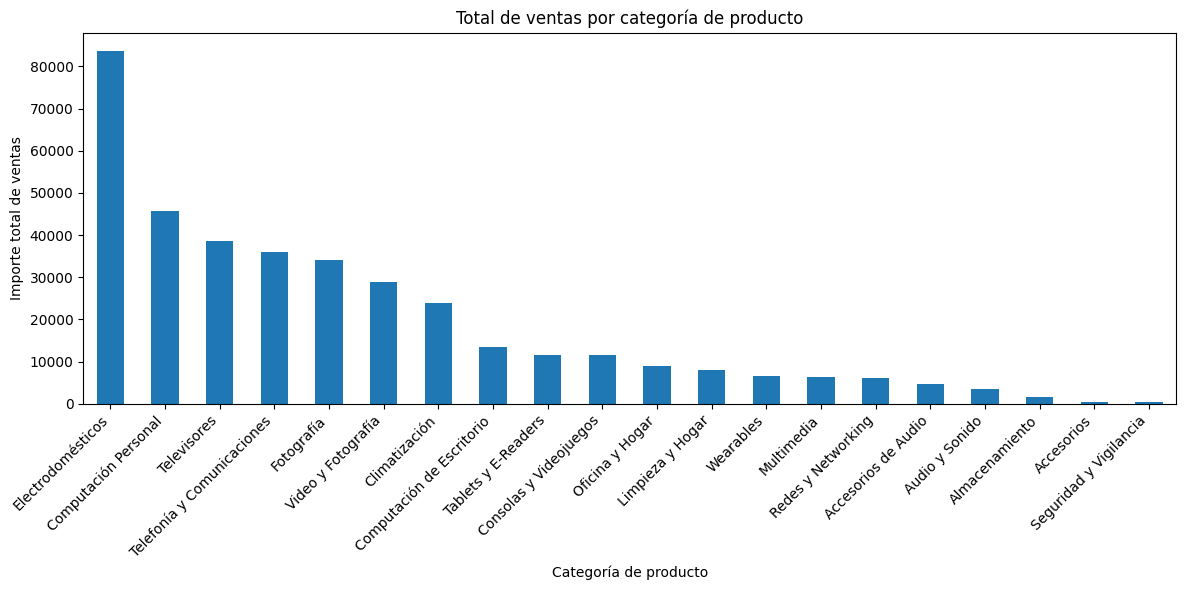

In [ ]:

# Consigna 6 — Análisis de ventas por categoría

import matplotlib.pyplot as plt

ventas_categoria = (
    ventas_productos
    .groupby("Categoría")["Total_Venta"]
    .sum()
    .sort_values(ascending=False)
)

print("Total de ventas por categoría:")
print(ventas_categoria)

# Gráfico de barras
plt.figure(figsize=(12, 6))

ventas_categoria.plot(kind="bar")

plt.title("Total de ventas por categoría de producto")
plt.xlabel("Categoría de producto")
plt.ylabel("Importe total de ventas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Conclusión final — Actividad 1: Análisis de Ventas y Productos

Se cargaron y exploraron tres conjuntos de datos correspondientes a ventas, productos y clientes.

Durante la limpieza se eliminaron 34 registros duplicados: 19 de ventas, 7 de productos y 8 de clientes. No se identificaron valores nulos y se verificó la unicidad de los identificadores principales. Además, se convirtieron las fechas al tipo `datetime` y los ingresos de clientes a valores numéricos.

Después de la limpieza quedaron 900 ventas, 36 productos y 100 clientes.

Se combinaron las tablas de ventas y productos mediante `ID_Producto`, conservando las 900 operaciones. Se calculó el importe de cada venta multiplicando la cantidad por el precio unitario y se obtuvo el gasto acumulado por cliente mediante una agrupación por `ID_Cliente`.

Finalmente, se agruparon los importes por categoría de producto y se representaron mediante un gráfico de barras ordenado de mayor a menor. Electrodomésticos fue la categoría con mayor importe de ventas, seguida por Computación Personal.

**Conclusión:** la consolidación de datos permitió integrar información de distintas fuentes, calcular indicadores comerciales y comparar el desempeño de las categorías de productos.

---
## Actividad 2: Análisis de Asistencia y Resultados en Talleres de Capacitación

### 1. Cargá los conjuntos de datos.

In [3]:

# Actividad 2 — 1. Cargá los conjuntos de datos.

import pandas as pd
from google.colab import drive

drive.mount("/content/drive")

ruta = "/content/drive/MyDrive/2026 - Data Analytics con Python/Data Sets Clase 12/"

talleres = pd.read_csv(ruta + "talleres.csv")
participantes = pd.read_csv(ruta + "participantes.csv")
resultados_taller = pd.read_csv(ruta + "resultados_taller.csv")

print("Talleres:", talleres.shape)
print("Participantes:", participantes.shape)
print("Resultados:", resultados_taller.shape)


Mounted at /content/drive
Talleres: (10, 2)
Participantes: (1014, 4)
Resultados: (1000, 4)


### 2. Explorá cada DataFrame para familiarizarte con los datos.

In [4]:

# Actividad 2 — 2. Explorá cada DataFrame para familiarizarte con los datos.

for nombre, df in {
    "Talleres": talleres,
    "Participantes": participantes,
    "Resultados": resultados_taller
}.items():
    print(f"\n{'=' * 15} {nombre} {'=' * 15}")

    print("\nPrimeras cinco filas:")
    display(df.head())

    print("\nEstructura y tipos de datos:")
    df.info()

    print("\nEstadísticas descriptivas:")
    display(df.describe(include="all"))



=============== Talleres ===============

Primeras cinco filas:


,ID_Taller,Nombre_Taller
0,1,Introducción al Análisis de Datos con Excel
1,2,Visualización de Datos con Power BI
2,3,Estadística para Análisis de Datos
3,4,Python para Análisis de Datos
4,5,Análisis de Datos con R



Estructura y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   ID_Taller      10 non-null     int64 
 1   Nombre_Taller  10 non-null     object
dtypes: int64(1), object(1)
memory usage: 292.0+ bytes

Estadísticas descriptivas:


,ID_Taller,Nombre_Taller
count,10.00000,10
unique,NaN,10
top,NaN,Introducción al Análisis de Datos con Excel
freq,NaN,1
mean,5.50000,NaN
std,3.02765,NaN
min,1.00000,NaN
25%,3.25000,NaN
50%,5.50000,NaN
75%,7.75000,NaN



=============== Participantes ===============

Primeras cinco filas:


,ID_Participante,Nombre,Edad,Ciudad
0,408,Jackquelin Gonzalo,34,Avellaneda
1,203,Natassia Endon,35,San Fernando
2,55,Daloris Fruser,40,Berisso
3,296,Addy Lorant,29,Tigre
4,427,Laurens Gladdor,33,Punta Lara


... (2 outputs left out)


=============== Resultados ===============

Primeras cinco filas:


,ID_Taller,ID_Participante,Asistió,Puntaje
0,5,35,False,4.36
1,9,989,True,3.48
2,6,636,True,8.15
3,2,742,True,6.85
4,10,170,True,4.51



Estructura y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID_Taller        1000 non-null   int64  
 1   ID_Participante  1000 non-null   int64  
 2   Asistió          1000 non-null   bool   
 3   Puntaje          996 non-null    float64
dtypes: bool(1), float64(1), int64(2)
memory usage: 24.5 KB

Estadísticas descriptivas:


,ID_Taller,ID_Participante,Asistió,Puntaje
count,1000.000000,1000.000000,1000,996.000000
unique,NaN,NaN,2,NaN
top,NaN,NaN,True,NaN
freq,NaN,NaN,925,NaN
mean,5.500000,500.500000,NaN,5.969247
std,2.873719,288.819436,NaN,1.480333
min,1.000000,1.000000,NaN,0.830000
25%,3.000000,250.750000,NaN,4.947500
50%,5.500000,500.500000,NaN,5.980000
75%,8.000000,750.250000,NaN,6.940000


### 3. Limpiá los datos.

In [5]:

# Actividad 2 — 3. Limpiá los datos.

for nombre, df in {
    "Talleres": talleres,
    "Participantes": participantes,
    "Resultados": resultados_taller
}.items():
    print(f"\n--- {nombre} ---")
    print("Registros:", len(df))
    print("Duplicados exactos:", df.duplicated().sum())
    print("Valores nulos:")
    print(df.isnull().sum())



--- Talleres ---
Registros: 10
Duplicados exactos: 0
Valores nulos:
ID_Taller        0
Nombre_Taller    0
dtype: int64

--- Participantes ---
Registros: 1014
Duplicados exactos: 14
Valores nulos:
ID_Participante    0
Nombre             0
Edad               0
Ciudad             0
dtype: int64

--- Resultados ---
Registros: 1000
Duplicados exactos: 0
Valores nulos:
ID_Taller          0
ID_Participante    0
Asistió            0
Puntaje            4
dtype: int64


In [6]:

# Actividad 2 — 3. Limpiá los datos.

# Eliminar duplicados exactos de participantes
participantes = participantes.drop_duplicates().copy()

# Conservar los puntajes faltantes como NaN
# Verificar el resultado de la limpieza
print("Talleres:", talleres.shape)
print("Participantes:", participantes.shape)
print("Resultados:", resultados_taller.shape)

print("\nDuplicados restantes en participantes:",
      participantes.duplicated().sum())

print("Puntajes faltantes:",
      resultados_taller["Puntaje"].isna().sum())

# Verificar identificadores de las tablas de referencia
print("ID_Taller repetidos:",
      talleres["ID_Taller"].duplicated().sum())

print("ID_Participante repetidos:",
      participantes["ID_Participante"].duplicated().sum())


Talleres: (10, 2)
Participantes: (1000, 4)
Resultados: (1000, 4)

Duplicados restantes en participantes: 0
Puntajes faltantes: 4
ID_Taller repetidos: 0
ID_Participante repetidos: 0


### 4. Combiná los tres conjuntos de datos en un único DataFrame utilizando las claves apropiadas.

In [7]:

# Actividad 2 — 4. Combiná los tres conjuntos de datos
# en un único DataFrame utilizando las claves apropiadas.

datos_consolidados = (
    resultados_taller
    .merge(
        talleres,
        on="ID_Taller",
        how="left",
        validate="many_to_one"
    )
    .merge(
        participantes,
        on="ID_Participante",
        how="left",
        validate="many_to_one"
    )
)

print("Registros originales:", len(resultados_taller))
print("Registros consolidados:", len(datos_consolidados))

print("\nValores faltantes por columna:")
print(datos_consolidados.isnull().sum())

display(datos_consolidados.head())


Registros originales: 1000
Registros consolidados: 1000

Valores faltantes por columna:
ID_Taller          0
ID_Participante    0
Asistió            0
Puntaje            4
Nombre_Taller      0
Nombre             0
Edad               0
Ciudad             0
dtype: int64


,ID_Taller,ID_Participante,Asistió,Puntaje,Nombre_Taller,Nombre,Edad,Ciudad
0,5,35,False,4.36,Análisis de Datos con R,Constantia Woodrup,32,San Fernando
1,9,989,True,3.48,Análisis Predictivo y Modelado Estadístico,Garold Gregoriou,28,Merlo
2,6,636,True,8.15,Minería de Datos y Machine Learning,Reggi Upward,32,La Matanza
3,2,742,True,6.85,Visualización de Datos con Power BI,Gloriane Munson,27,Malvinas Argentinas
4,10,170,True,4.51,Data Science para No Científicos,Zeke Adamkiewicz,37,Punta Lara


### 5. Realizá un análisis para calcular la asistencia promedio a los talleres y el puntaje promedio obtenido por los participantes, visualizando los resultados en gráficos.

Resumen de asistencia y puntajes por taller:


,Asistencia_Promedio,Puntaje_Promedio
Nombre_Taller,,
Data Science para No Científicos,96.0,6.16
Minería de Datos y Machine Learning,94.0,6.14
Visualización de Datos con Power BI,94.0,5.92
Análisis Predictivo y Modelado Estadístico,93.0,5.77
Introducción al Análisis de Datos con Excel,93.0,5.87
Big Data y Procesamiento de Datos,93.0,5.78
Python para Análisis de Datos,92.0,6.11
Análisis de Datos con R,91.0,6.15
Estadística para Análisis de Datos,90.0,6.02


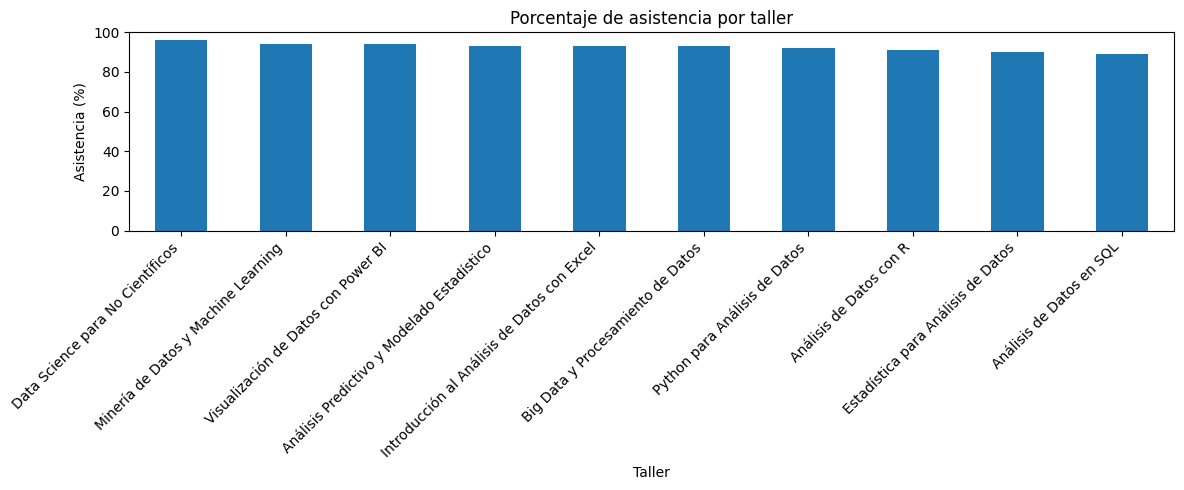

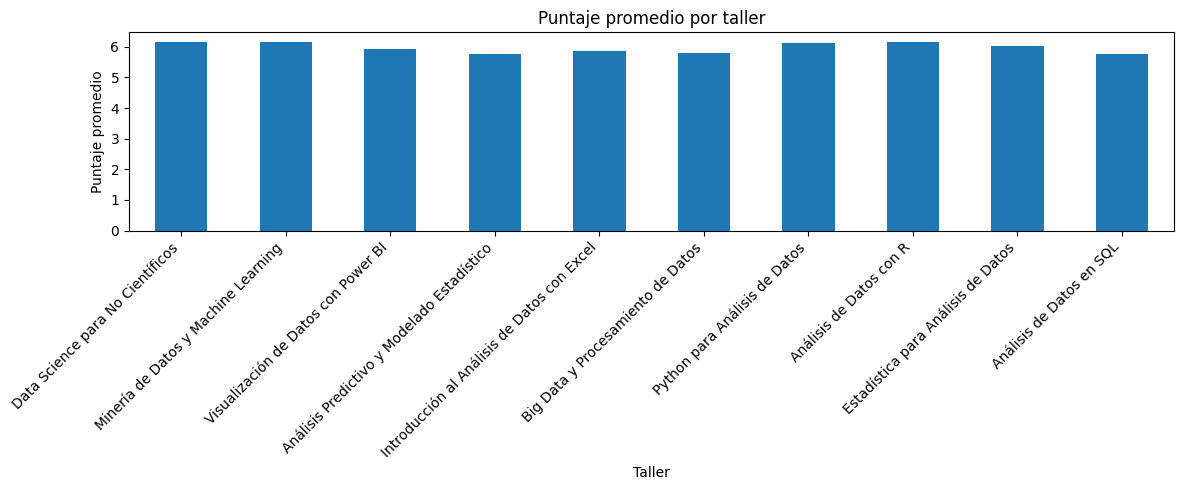

In [8]:

# Actividad 2 — Consigna 5:
# Asistencia y puntaje promedio por taller

import matplotlib.pyplot as plt

resumen_talleres = (
    datos_consolidados
    .groupby("Nombre_Taller")
    .agg(
        Asistencia_Promedio=("Asistió", "mean"),
        Puntaje_Promedio=("Puntaje", "mean")
    )
    .sort_values("Asistencia_Promedio", ascending=False)
)

# Expresar la asistencia como porcentaje
resumen_talleres["Asistencia_Promedio"] *= 100

print("Resumen de asistencia y puntajes por taller:")
display(resumen_talleres.round(2))

# Gráfico 1: Asistencia promedio
resumen_talleres["Asistencia_Promedio"].plot(
    kind="bar", figsize=(12, 5)
)
plt.title("Porcentaje de asistencia por taller")
plt.xlabel("Taller")
plt.ylabel("Asistencia (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Gráfico 2: Puntaje promedio
resumen_talleres["Puntaje_Promedio"].plot(
    kind="bar", figsize=(12, 5)
)
plt.title("Puntaje promedio por taller")
plt.xlabel("Taller")
plt.ylabel("Puntaje promedio")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Conclusión final — Actividad 2: Análisis de Asistencia y Resultados en Talleres de Capacitación

Se cargaron y exploraron tres conjuntos de datos correspondientes a talleres, participantes y resultados de las capacitaciones.

Durante la limpieza se eliminaron 14 registros duplicados del dataset de participantes. No se identificaron duplicados en talleres ni en resultados. Se conservaron cuatro puntajes faltantes para evitar introducir calificaciones artificiales.

Después de la limpieza quedaron 10 talleres, 1.000 participantes y 1.000 registros de resultados.

Los tres conjuntos de datos se combinaron utilizando las columnas `ID_Taller` e `ID_Participante`, obteniendo un DataFrame consolidado de 1.000 registros, sin pérdidas de información ni nuevos valores faltantes.

Finalmente, se calculó el porcentaje de asistencia y el puntaje promedio por taller, representando ambos indicadores mediante gráficos de barras.

Los resultados muestran una asistencia elevada en todos los talleres, con porcentajes aproximados de entre 89 % y 98 %. Los puntajes promedio presentan diferencias relativamente pequeñas entre las capacitaciones.